# ¿Cuál es la mejor tarifa?

Trabajas como analista para el operador de telecomunicaciones Megaline. La empresa ofrece a sus clientes dos tarifas de prepago, Surf y Ultimate. El departamento comercial quiere saber cuál de las tarifas genera más ingresos para poder ajustar el presupuesto de publicidad.

Vas a realizar un análisis preliminar de las tarifas basado en una selección de clientes relativamente pequeña. Tendrás los datos de 500 clientes de Megaline: quiénes son los clientes, de dónde son, qué tarifa usan, así como la cantidad de llamadas que hicieron y los mensajes de texto que enviaron en 2018. Tu trabajo es analizar el comportamiento de los clientes y determinar qué tarifa de prepago genera más ingresos.

Mi objetivo en este proyecto sera analizar datos de 500 clientes con el fin de analizar el comportamiento de los clientes y poder calcular que tarifa de prepago generó mas ingresos a lo largo de 1 año, usaré pruebas estadisticas para respaldar mis concluciones

## Inicialización

In [1]:
# Cargar todas las librerías
import pandas as pd
import math
import matplotlib.pyplot as plt
from scipy import stats

## Cargar datos

In [2]:
# Carga los archivos de datos en diferentes DataFrames
users = pd.read_csv("/datasets/megaline_users.csv")
calls = pd.read_csv("/datasets/megaline_calls.csv")
messages = pd.read_csv("/datasets/megaline_messages.csv")
internet = pd.read_csv("/datasets/megaline_internet.csv")
plans = pd.read_csv("/datasets/megaline_plans.csv")

# Aqui cargo todas las tablas y las asigno a variables descriptivas (en ingles)

## Preparar los datos

In [3]:
#La verdad esta parte fue muy confusa, se supone que aquí debia poner algo pero segun DOT aqui no habia que poner nada.
#Continue mi trabajo abajo, en caso que esto este mal lo corregiré despues de la revisión.

## Tarifas

In [4]:
# Imprime la información general/resumida sobre el DataFrame de las tarifas
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes


In [5]:
# Imprime una muestra de los datos para las tarifas
plans.head()

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


In [6]:
#Reviso si hay valores ausentes o duplicados (hago la revision usando duplicated().sum() pero solo dejo ese codigo)
plans.isnull().sum()

messages_included        0
mb_per_month_included    0
minutes_included         0
usd_monthly_pay          0
usd_per_gb               0
usd_per_message          0
usd_per_minute           0
plan_name                0
dtype: int64

Observando los resultados el DataFrame esta bastante limpio, todas las columnas tienen valores adecuados, no hay valores ausentes ni valores duplicados, y hay nombres correctos, asi que todo perfecto en este.

## Corregir datos

No hay nada que corregir en este DataFrame

## Enriquecer los datos

Todos los datos estaban muy limpios, pero analizando el dataframe considere adecuado agregar una nueva columna que calcule lo mismo que la columna mb_per_month_included pero ahora en GB

In [7]:
nombres_organizados = ["messages_included", "mb_per_month_included", "gb_per_month_included", "minutes_included", "usd_monthly_pay", "usd_per_gb", "usd_per_message", "usd_per_minute", "plan_name"]

plans["gb_per_month_included"] = plans["mb_per_month_included"] / 1024
plans["gb_per_month_included"] = plans["gb_per_month_included"].astype(int)
plans = plans[nombres_organizados]
plans.head()

#Aqui cree una nueva columna que calcule en Gigabytes que incluye cada plan, probablemente facilite calculos futuros tener una columna en Megabytes y en Gigabytes

,messages_included,mb_per_month_included,gb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,15,500,20,10,0.03,0.03,surf
1,1000,30720,30,3000,70,7,0.01,0.01,ultimate


## Usuarios/as

In [8]:
# Imprime la información general/resumida sobre el DataFrame de usuarios
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


In [9]:
# Imprime una muestra de datos para usuarios
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaN
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaN
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaN
3,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,surf,NaN
4,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,surf,NaN


In [10]:
#Reviso si hay valores ausentes o duplicados (hago la revision usando duplicated().sum() pero solo dejo ese codigo)
users.isnull().sum()

user_id         0
first_name      0
last_name       0
age             0
city            0
reg_date        0
plan            0
churn_date    466
dtype: int64

Aqui puedo encontrar 2 problemas, el primero es que las columnas reg_date(fecha de suscripción) y churn_date(fecha de cuando el usuario dejo de usar el servicio) tienen valores object, y deberian tener valores datetime, y el segundo es que la columna churn_date tiene 466 valores ausentes, y aunque estos valores ausentes tienen sentido porque indica que la tarifa seguia activa cuando se tomaron los datos, hay una forma de convertirla a una manera mas entendible y adecuada

### Corregir los datos

In [11]:
#Aqui convierto la columna al formato correcto y verifico los resultados con otro info()
users["reg_date"] = pd.to_datetime(users["reg_date"])
users["churn_date"] = pd.to_datetime(users["churn_date"])
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    object        
 2   last_name   500 non-null    object        
 3   age         500 non-null    int64         
 4   city        500 non-null    object        
 5   reg_date    500 non-null    datetime64[ns]
 6   plan        500 non-null    object        
 7   churn_date  34 non-null     datetime64[ns]
dtypes: datetime64[ns](2), int64(2), object(4)
memory usage: 31.4+ KB


### Enriquecer los datos

No considero necesario enriquecer los datos

## Llamadas

In [12]:
# Imprime la información general/resumida sobre el DataFrame de las llamadas
calls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB


In [13]:
# Imprime una muestra de datos para las llamadas
calls.head()

,id,user_id,call_date,duration
0,1000_93,1000,2018-12-27,8.52
1,1000_145,1000,2018-12-27,13.66
2,1000_247,1000,2018-12-27,14.48
3,1000_309,1000,2018-12-28,5.76
4,1000_380,1000,2018-12-30,4.22


In [14]:
#Reviso si hay valores ausentes o duplicados (hago la revision usando duplicated().sum() pero solo dejo ese codigo)
calls.isnull().sum()

id           0
user_id      0
call_date    0
duration     0
dtype: int64

El único problema que encontre es que la columna call_date esta en formato object, no hay otro problema en las columnas ni hay valores duplicados o ausentes

### Corregir los datos

In [15]:
#Aqui convierto la columna al formato correcto y verifico los resultados con otro info()
calls["call_date"] = pd.to_datetime(calls["call_date"])
calls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  object        
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[ns]
 3   duration   137735 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 4.2+ MB


### Enriquecer los datos

In [16]:
#Aqui cree una nueva columna que muestre el mes de cada llamada, considero que sera util para analisis futuros
calls["month_of_call"] = calls["call_date"].dt.month
calls.head(30)

,id,user_id,call_date,duration,month_of_call
0,1000_93,1000,2018-12-27,8.52,12
1,1000_145,1000,2018-12-27,13.66,12
2,1000_247,1000,2018-12-27,14.48,12
3,1000_309,1000,2018-12-28,5.76,12
4,1000_380,1000,2018-12-30,4.22,12
5,1000_388,1000,2018-12-31,2.20,12
6,1000_510,1000,2018-12-27,5.75,12
7,1000_521,1000,2018-12-28,14.18,12
8,1000_530,1000,2018-12-28,5.77,12
9,1000_544,1000,2018-12-26,4.40,12


## Mensajes

In [17]:
# Imprime la información general/resumida sobre el DataFrame de los mensajes
messages.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


In [18]:
# Imprime una muestra de datos para los mensajes
messages.head()

,id,user_id,message_date
0,1000_125,1000,2018-12-27
1,1000_160,1000,2018-12-31
2,1000_223,1000,2018-12-31
3,1000_251,1000,2018-12-27
4,1000_255,1000,2018-12-26


In [19]:
#Reviso si hay valores ausentes o duplicados (hago la revision usando duplicated().sum() pero solo dejo ese codigo)
messages.isnull().sum()

id              0
user_id         0
message_date    0
dtype: int64

Aqui el problema es el mismo, la columna message_date esta en formato object, y debe estar en datetime, para el resto del DataFrame no veo ningún problema

### Corregir los datos

In [20]:
#Convierto la columna al formato datetime y verifico resultados con info()
messages["message_date"] = pd.to_datetime(messages["message_date"])
messages.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB


### Enriquecer los datos

In [21]:
#Creo una nueva columna esta vez con el mes de cada mensaje, considero que sera util para analisis futuros
messages["month_of_message"] = messages["message_date"].dt.month
messages.head(30)

,id,user_id,message_date,month_of_message
0,1000_125,1000,2018-12-27,12
1,1000_160,1000,2018-12-31,12
2,1000_223,1000,2018-12-31,12
3,1000_251,1000,2018-12-27,12
4,1000_255,1000,2018-12-26,12
5,1000_346,1000,2018-12-29,12
6,1000_386,1000,2018-12-30,12
7,1000_413,1000,2018-12-31,12
8,1000_502,1000,2018-12-27,12
9,1000_525,1000,2018-12-28,12


## Internet

In [22]:

# Imprime la información general/resumida sobre el DataFrame de internet
internet.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB


In [23]:
# Imprime una muestra de datos para el tráfico de internet
internet.head()

,id,user_id,session_date,mb_used
0,1000_13,1000,2018-12-29,89.86
1,1000_204,1000,2018-12-31,0.00
2,1000_379,1000,2018-12-28,660.40
3,1000_413,1000,2018-12-26,270.99
4,1000_442,1000,2018-12-27,880.22


Aqui nuevamente esta el problema del formato, session_date esta en formato object, debe estar en datetime

In [24]:
#Reviso si hay valores ausentes o duplicados (hago la revision usando duplicated().sum() pero solo dejo ese codigo)
internet.isnull().sum()

id              0
user_id         0
session_date    0
mb_used         0
dtype: int64

### Corregir los datos

In [25]:
#Convierto la columna al formato datetime y verifico resultados con info()
internet["session_date"] = pd.to_datetime(internet["session_date"])
internet.head(30)

,id,user_id,session_date,mb_used
0,1000_13,1000,2018-12-29,89.86
1,1000_204,1000,2018-12-31,0.00
2,1000_379,1000,2018-12-28,660.40
3,1000_413,1000,2018-12-26,270.99
4,1000_442,1000,2018-12-27,880.22
5,1001_0,1001,2018-08-24,284.68
6,1001_3,1001,2018-12-09,656.04
7,1001_4,1001,2018-11-04,16.97
8,1001_10,1001,2018-11-27,135.18
9,1001_15,1001,2018-12-13,761.92


### Enriquecer los datos

In [26]:
#Aqui creo 2 nuevas columnas, una que muestre el consumo de Megabytes pero en Gigabytes, y otra para mostrar el mes de cada session_date
nombres_organizados = ["id", "user_id", "session_date", "month_of_session", "mb_used", "gb_used"]

internet["gb_used"] = internet["mb_used"] / 1024
internet["month_of_session"] = internet["session_date"].dt.month
internet = internet[nombres_organizados]

internet.head(30)

,id,user_id,session_date,month_of_session,mb_used,gb_used
0,1000_13,1000,2018-12-29,12,89.86,0.087754
1,1000_204,1000,2018-12-31,12,0.00,0.000000
2,1000_379,1000,2018-12-28,12,660.40,0.644922
3,1000_413,1000,2018-12-26,12,270.99,0.264639
4,1000_442,1000,2018-12-27,12,880.22,0.859590
5,1001_0,1001,2018-08-24,8,284.68,0.278008
6,1001_3,1001,2018-12-09,12,656.04,0.640664
7,1001_4,1001,2018-11-04,11,16.97,0.016572
8,1001_10,1001,2018-11-27,11,135.18,0.132012
9,1001_15,1001,2018-12-13,12,761.92,0.744062


## Estudiar las condiciones de las tarifas

In [27]:
# Imprime las condiciones de la tarifa y asegúrate de que te quedan claras
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   gb_per_month_included  2 non-null      int64  
 3   minutes_included       2 non-null      int64  
 4   usd_monthly_pay        2 non-null      int64  
 5   usd_per_gb             2 non-null      int64  
 6   usd_per_message        2 non-null      float64
 7   usd_per_minute         2 non-null      float64
 8   plan_name              2 non-null      object 
dtypes: float64(2), int64(6), object(1)
memory usage: 272.0+ bytes


## Agregar datos por usuario

[Ahora que los datos están limpios, agrega los datos por usuario y por periodo para que solo haya un registro por usuario y por periodo. Esto facilitará mucho el análisis posterior.]

In [28]:
# Calcula el número de llamadas hechas por cada usuario al mes. Guarda el resultado.
conteo = calls.groupby(["user_id", "month_of_call"])
conteo_de_llamadas = conteo.size()
conteo_de_llamadas = conteo.size().reset_index().rename(columns={0: "calls_count"})
print(conteo_de_llamadas)

      user_id  month_of_call  calls_count
0        1000             12           16
1        1001              8           27
2        1001              9           49
3        1001             10           65
4        1001             11           64
...       ...            ...          ...
2253     1498             12           39
2254     1499              9           41
2255     1499             10           53
2256     1499             11           45
2257     1499             12           65

[2258 rows x 3 columns]


In [29]:
# Calcula la cantidad de minutos usados por cada usuario al mes. Guarda el resultado.
calls["minutes_per_user"] = calls["duration"].apply(math.ceil)
conteo2 = calls.groupby(["user_id", "month_of_call"])
total_de_minutos = conteo2["minutes_per_user"].sum()
total_de_minutos = total_de_minutos.reset_index()
print(total_de_minutos)

      user_id  month_of_call  minutes_per_user
0        1000             12               124
1        1001              8               182
2        1001              9               315
3        1001             10               393
4        1001             11               426
...       ...            ...               ...
2253     1498             12               339
2254     1499              9               346
2255     1499             10               385
2256     1499             11               308
2257     1499             12               496

[2258 rows x 3 columns]


In [30]:
# Calcula el número de mensajes enviados por cada usuario al mes. Guarda el resultado.
conteo3 = messages.groupby(["user_id", "month_of_message"])
conteo_de_mensajes = conteo3.size()
conteo_de_mensajes = conteo3.size().reset_index().rename(columns={0: "messages_count"})
print(conteo_de_mensajes)

      user_id  month_of_message  messages_count
0        1000                12              11
1        1001                 8              30
2        1001                 9              44
3        1001                10              53
4        1001                11              36
...       ...               ...             ...
1801     1496                 9              21
1802     1496                10              18
1803     1496                11              13
1804     1496                12              11
1805     1497                12              50

[1806 rows x 3 columns]


In [31]:
# Calcula el volumen del tráfico de Internet usado por cada usuario al mes. Guarda el resultado.
conteo4 = internet.groupby(["user_id", "month_of_session"])
volumen_de_consumo = conteo4["gb_used"].sum()
volumen_de_consumo = volumen_de_consumo.reset_index()
print(volumen_de_consumo)

      user_id  month_of_session    gb_used
0        1000                12   1.856904
1        1001                 8   6.756982
2        1001                 9  13.002754
3        1001                10  21.807119
4        1001                11  18.070605
...       ...               ...        ...
2272     1498                12  22.595400
2273     1499                 9  12.680430
2274     1499                10  19.035576
2275     1499                11  16.419756
2276     1499                12  21.542197

[2277 rows x 3 columns]


In [32]:

# Fusiona los datos de llamadas, minutos, mensajes e Internet con base en user_id y month
conteo_de_llamadas = conteo_de_llamadas.rename(columns={"month_of_call": "month"})
total_de_minutos = total_de_minutos.rename(columns={"month_of_call": "month"})
volumen_de_consumo = volumen_de_consumo.rename(columns={"month_of_session": "month"})
conteo_de_mensajes = conteo_de_mensajes.rename(columns={"month_of_message": "month"})


datos_combinados = conteo_de_llamadas.merge(total_de_minutos, on = ["user_id", "month"], how="left").merge(volumen_de_consumo, on = ["user_id", "month"], how="left").merge(conteo_de_mensajes, on = ["user_id", "month"], how="left")
datos_combinados["messages_count"] = datos_combinados["messages_count"].fillna(0).astype(int)

print(datos_combinados)


#Aqui primero intente encadenar los dataframes usando left_on y right_on para unirlos por columnas con diferentes nombres, pero al final
#descubri que era mejor renombrar las columnas para que todas tuvieran el mismo nombre y solo usar on =.
#Encandene todas y les asigne un how="left" a todos los merge() para conservar valores ausentes en caso de que los haya, y despues reemplace esos valores ausentes con 0 y lo convertí a enteros.

      user_id  month  calls_count  minutes_per_user    gb_used  messages_count
0        1000     12           16               124   1.856904              11
1        1001      8           27               182   6.756982              30
2        1001      9           49               315  13.002754              44
3        1001     10           65               393  21.807119              53
4        1001     11           64               426  18.070605              36
...       ...    ...          ...               ...        ...             ...
2253     1498     12           39               339  22.595400               0
2254     1499      9           41               346  12.680430               0
2255     1499     10           53               385  19.035576               0
2256     1499     11           45               308  16.419756               0
2257     1499     12           65               496  21.542197               0

[2258 rows x 6 columns]


In [33]:
# Añade la información de la tarifa
datos_organizados = datos_combinados.merge(users, on = "user_id", how="left")
print(datos_organizados)

      user_id  month  calls_count  minutes_per_user    gb_used  \
0        1000     12           16               124   1.856904   
1        1001      8           27               182   6.756982   
2        1001      9           49               315  13.002754   
3        1001     10           65               393  21.807119   
4        1001     11           64               426  18.070605   
...       ...    ...          ...               ...        ...   
2253     1498     12           39               339  22.595400   
2254     1499      9           41               346  12.680430   
2255     1499     10           53               385  19.035576   
2256     1499     11           45               308  16.419756   
2257     1499     12           65               496  21.542197   

      messages_count first_name   last_name  age  \
0                 11   Anamaria       Bauer   45   
1                 30     Mickey   Wilkerson   28   
2                 44     Mickey   Wilkerson   28   

In [34]:


# Calcula el ingreso mensual para cada usuario
datos_organizados = datos_organizados.merge(plans, left_on = "plan", right_on = "plan_name", how="left")

minutos_extra = (datos_organizados["minutes_per_user"] - datos_organizados["minutes_included"]).clip(lower=0)
datos_organizados["extra_minutes_per_user"] = minutos_extra * datos_organizados["usd_per_minute"]


mensajes_extra = (datos_organizados["messages_count"] - datos_organizados["messages_included"]).clip(lower=0)
datos_organizados["extra_messages_per_user"] = mensajes_extra * datos_organizados["usd_per_message"]



gigabytes_extra = (datos_organizados["gb_used"] - datos_organizados["gb_per_month_included"]).clip(lower=0)
datos_organizados["extra_gb_per_user"] = gigabytes_extra * datos_organizados["usd_per_gb"]



datos_organizados["total_usd_monthly_pay"] = datos_organizados["usd_monthly_pay"] + datos_organizados["extra_minutes_per_user"] + datos_organizados["extra_messages_per_user"] + datos_organizados["extra_gb_per_user"]

print(datos_organizados)

#El codigo esta raro porque da error, pero si se restablece kernel o se ejecuta primero el codigo anterior sale bien.

      user_id  month  calls_count  minutes_per_user    gb_used  \
0        1000     12           16               124   1.856904   
1        1001      8           27               182   6.756982   
2        1001      9           49               315  13.002754   
3        1001     10           65               393  21.807119   
4        1001     11           64               426  18.070605   
...       ...    ...          ...               ...        ...   
2253     1498     12           39               339  22.595400   
2254     1499      9           41               346  12.680430   
2255     1499     10           53               385  19.035576   
2256     1499     11           45               308  16.419756   
2257     1499     12           65               496  21.542197   

      messages_count first_name   last_name  age  \
0                 11   Anamaria       Bauer   45   
1                 30     Mickey   Wilkerson   28   
2                 44     Mickey   Wilkerson   28   

## Estudia el comportamiento de usuario

### Llamadas

Text(0.5, 0, 'Planes')

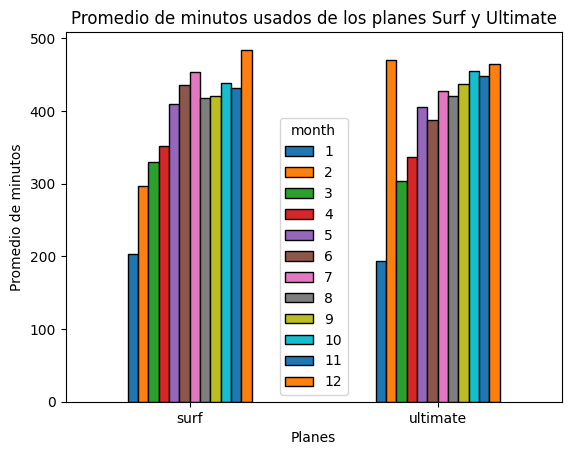

In [35]:

# Compara la duración promedio de llamadas por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.
promedio_de_llamadas = datos_organizados.groupby(["plan", "month"])["minutes_per_user"].mean()
grafica_de_llamadas = promedio_de_llamadas.unstack()
grafica_de_llamadas.plot(kind="bar",title="Promedio de minutos usados de los planes Surf y Ultimate",rot=0, edgecolor="black")
plt.ylabel("Promedio de minutos")
plt.xlabel("Planes")


Text(0.5, 0, 'Promedio de minutos')

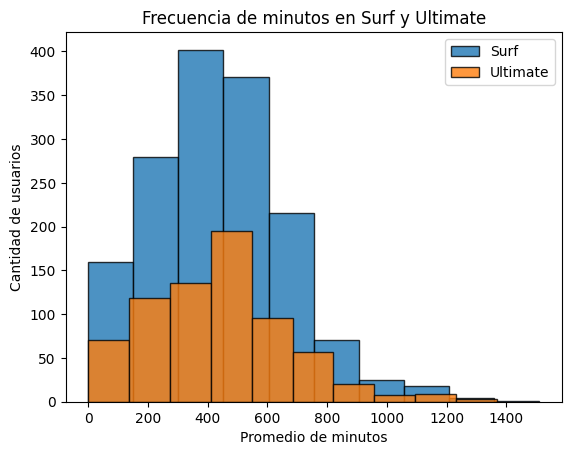

In [36]:
# Compara el número de minutos mensuales que necesitan los usuarios de cada plan. Traza un histograma.
histograma_surf_minutos = datos_organizados[datos_organizados["plan"] == "surf"]["minutes_per_user"]
histograma_ultimate_minutos = datos_organizados[datos_organizados["plan"] == "ultimate"]["minutes_per_user"]
histograma_surf_minutos.plot(kind="hist", alpha=0.8, title="Frecuencia de minutos en Surf y Ultimate", label="Surf", edgecolor="black")
histograma_ultimate_minutos.plot(kind="hist", alpha=0.8, label="Ultimate", edgecolor="black")
plt.legend()
plt.ylabel("Cantidad de usuarios")
plt.xlabel("Promedio de minutos")

In [37]:
# Calcula la media y la varianza de la duración mensual de llamadas.
datos_surf_minutos = datos_organizados[datos_organizados["plan"] == "surf"]["minutes_per_user"]
datos_ultimate_minutos = datos_organizados[datos_organizados["plan"] == "ultimate"]["minutes_per_user"]
media_surf = datos_surf_minutos.mean()
varianza_surf = datos_surf_minutos.var()
media_ultimate = datos_ultimate_minutos.mean()
varianza_ultimate = datos_ultimate_minutos.var()

print(f"La media de los datos de surf es", media_surf)
print(f"La varianza de los datos de surf es", varianza_surf)
print()
print(f"La media de los datos de ultimate es", media_ultimate)
print(f"La varianza de los datos de ultimate es", varianza_ultimate)

La media de los datos de surf es 436.51974110032364
La varianza de los datos de surf es 52571.06324345624

La media de los datos de ultimate es 434.67601683029454
La varianza de los datos de ultimate es 56573.63224703341


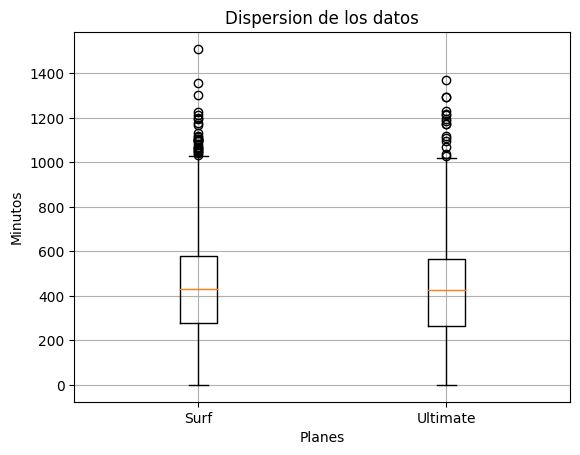

In [38]:
# Traza un diagrama de caja para visualizar la distribución de la duración mensual de llamadas

plt.boxplot([datos_surf_minutos, datos_ultimate_minutos], labels=["Surf", "Ultimate"])
plt.title("Dispersion de los datos")
plt.xlabel("Planes")
plt.ylabel("Minutos")
plt.grid()


El análisis de las llamadas muestra que el consumo promedio de minutos entre ambos planes es bastante similar. Los usuarios del plan Surf presentan una media aproximada de 436.52 minutos por mes, mientras que los usuarios del plan Ultimate registran una media cercana a 434.68 minutos.

En cuanto a la variabilidad de los datos, el plan Surf tiene una varianza aproximada de 52,571, mientras que el plan Ultimate presenta una varianza ligeramente mayor de 56,573. Esto indica que, aunque ambos planes tienen promedios muy parecidos, los usuarios del plan Ultimate muestran una dispersión un poco más amplia en el uso de minutos, es decir, existen más diferencias entre usuarios con consumos bajos y altos dentro de este plan.

Además, las gráficas permiten observar la presencia de valores atípicos en ambos planes, correspondientes a usuarios con un consumo de llamadas considerablemente superior al promedio. En general, los resultados sugieren que el comportamiento de llamadas entre ambos planes es muy similar, aunque el plan Ultimate presenta una ligera mayor variabilidad en el consumo de minutos.


### Mensajes

Text(0.5, 0, 'Planes')

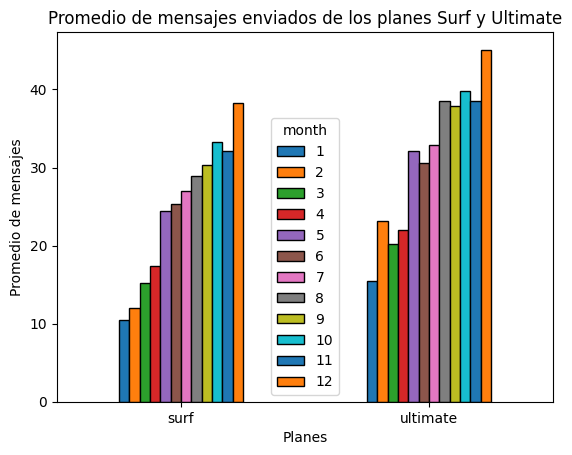

In [39]:
# Comprara el número de mensajes que tienden a enviar cada mes los usuarios de cada plan
promedio_de_mensajes = datos_organizados.groupby(["plan", "month"])["messages_count"].mean()
grafica_de_mensajes = promedio_de_mensajes.unstack()
grafica_de_mensajes.plot(kind="bar",title="Promedio de mensajes enviados de los planes Surf y Ultimate",rot=0, edgecolor="black")
plt.ylabel("Promedio de mensajes")
plt.xlabel("Planes")


Text(0.5, 0, 'Promedio de mensajes enviados')

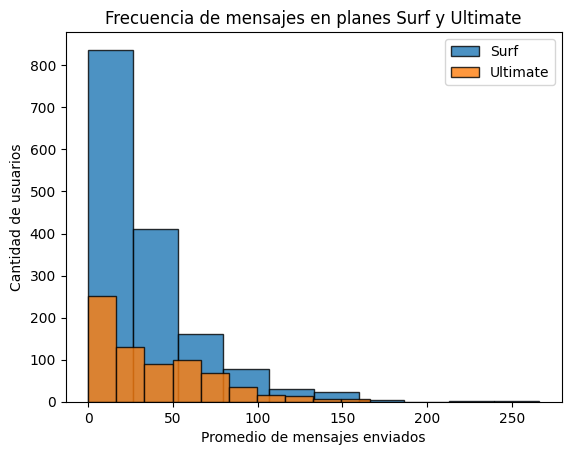

In [40]:
histograma_surf_mensajes = datos_organizados[datos_organizados["plan"] == "surf"]["messages_count"]
histograma_ultimate_mensajes = datos_organizados[datos_organizados["plan"] == "ultimate"]["messages_count"]
histograma_surf_mensajes.plot(kind="hist", alpha=0.8, title="Frecuencia de mensajes en planes Surf y Ultimate", label="Surf", edgecolor="black")
histograma_ultimate_mensajes.plot(kind="hist", alpha=0.8, label="Ultimate", edgecolor="black")
plt.legend()
plt.ylabel("Cantidad de usuarios")
plt.xlabel("Promedio de mensajes enviados")

In [41]:
datos_surf_mensajes = datos_organizados[datos_organizados["plan"] == "surf"]["messages_count"]
datos_ultimate_mensajes = datos_organizados[datos_organizados["plan"] == "ultimate"]["messages_count"]

media_surf_mensajes = datos_surf_mensajes.mean()
varianza_surf_mensajes = datos_surf_mensajes.var()
media_ultimate_mensajes = datos_ultimate_mensajes.mean()
varianza_ultimate_mensajes = datos_ultimate_mensajes.var()

print(f"La media de los datos de surf es", media_surf_mensajes)
print(f"La varianza de los datos de surf es", varianza_surf_mensajes)
print()
print(f"La media de los datos de ultimate es", media_ultimate_mensajes)
print(f"La varianza de los datos de ultimate es", varianza_ultimate_mensajes)

La media de los datos de surf es 30.897734627831714
La varianza de los datos de surf es 1131.9493795797912

La media de los datos de ultimate es 37.725105189340816
La varianza de los datos de ultimate es 1210.143427833021


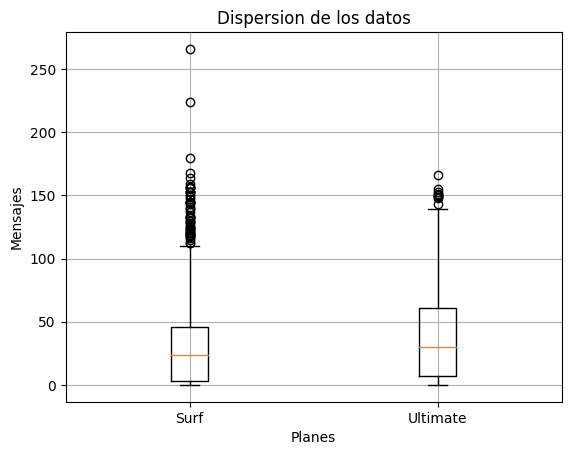

In [42]:
datos_surf_mensajes = datos_organizados[datos_organizados["plan"] == "surf"]["messages_count"]
datos_ultimate_mensajes = datos_organizados[datos_organizados["plan"] == "ultimate"]["messages_count"]
plt.boxplot([datos_surf_mensajes, datos_ultimate_mensajes], labels=["Surf", "Ultimate"])
plt.title("Dispersion de los datos")
plt.xlabel("Planes")
plt.ylabel("Mensajes")
plt.grid()

El análisis de las gráficas de mensajes muestra que el consumo de SMS no sigue una distribución normal y se encuentra fuertemente influenciado por un grupo reducido de usuarios con consumos muy elevados. Tanto el histograma como los diagramas de caja evidencian una distribución sesgada hacia la derecha, donde la mayoría de usuarios se concentra en consumos moderados inferiores a 50 mensajes mensuales.

Los usuarios del plan Ultimate presentan un promedio de consumo más alto, con aproximadamente 37.73 mensajes mensuales frente a los 30.90 del plan Surf. Además, las varianzas relativamente altas en ambos planes (1131.95 en Surf y 1210.14 en Ultimate) indican una dispersión considerable en el comportamiento de los usuarios y la presencia de múltiples valores atípicos.

El boxplot confirma esta situación al mostrar numerosos outliers, especialmente en el plan Surf, donde algunos usuarios superan ampliamente el consumo habitual del resto de clientes. Esto sugiere que existe un pequeño grupo de usuarios intensivos cuyo comportamiento eleva significativamente el promedio general del plan.

Desde una perspectiva de negocio, estos usuarios intensivos del plan Surf podrían representar una oportunidad importante para campañas de migración hacia el plan Ultimate, especialmente si los costos por excedentes terminan siendo más altos que una tarifa mensual superior.


### Internet

Text(0.5, 0, 'Planes')

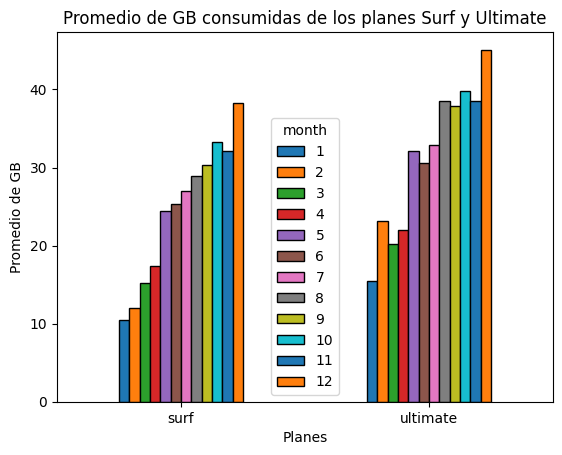

In [43]:
promedio_de_GB = datos_organizados.groupby(["plan", "month"])["gb_used"].mean()
grafica_de_GB = promedio_de_mensajes.unstack()
grafica_de_GB.plot(kind="bar",title="Promedio de GB consumidas de los planes Surf y Ultimate",rot=0, edgecolor="black")
plt.ylabel("Promedio de GB")
plt.xlabel("Planes")

Text(0.5, 0, 'Promedio de GB usadas')

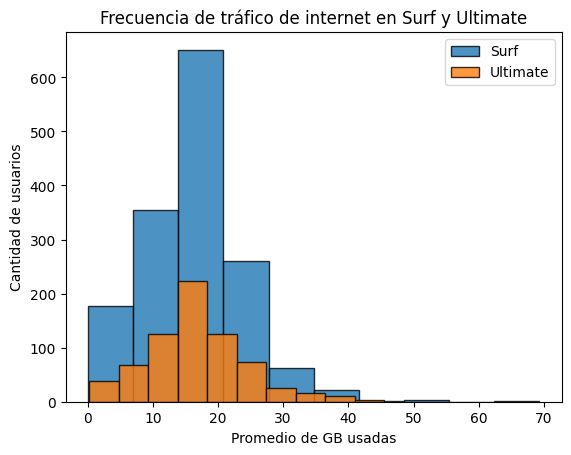

In [68]:
histograma_surf_GB = datos_organizados[datos_organizados["plan"] == "surf"]["gb_used"]
histograma_surf_GB = histograma_surf_GB.dropna()
histograma_ultimate_GB = datos_organizados[datos_organizados["plan"] == "ultimate"]["gb_used"]
histograma_surf_GB.plot(kind="hist", alpha=0.8, title="Frecuencia de tráfico de internet en Surf y Ultimate", label="Surf", edgecolor="black")
histograma_ultimate_GB.plot(kind="hist", alpha=0.8, label="Ultimate", edgecolor="black")
plt.legend()
plt.ylabel("Cantidad de usuarios")
plt.xlabel("Promedio de GB usadas")

In [69]:
datos_surf_internet = datos_organizados[datos_organizados["plan"] == "surf"]["gb_used"]
datos_ultimate_internet = datos_organizados[datos_organizados["plan"] == "ultimate"]["gb_used"]

media_surf_internet = datos_surf_internet.mean()
varianza_surf_internet = datos_surf_internet.var()
media_ultimate_internet = datos_ultimate_internet.mean()
varianza_ultimate_internet = datos_ultimate_internet.var()

print(f"La media de los datos de surf es", media_surf_internet)
print(f"La varianza de los datos de surf es", varianza_surf_internet)
print()
print(f"La media de los datos de ultimate es", media_ultimate_internet)
print(f"La varianza de los datos de ultimate es", varianza_ultimate_internet)

La media de los datos de surf es 16.27690256714665
La varianza de los datos de surf es 56.73742275912101

La media de los datos de ultimate es 16.87305051827665
La varianza de los datos de ultimate es 57.422874741448815


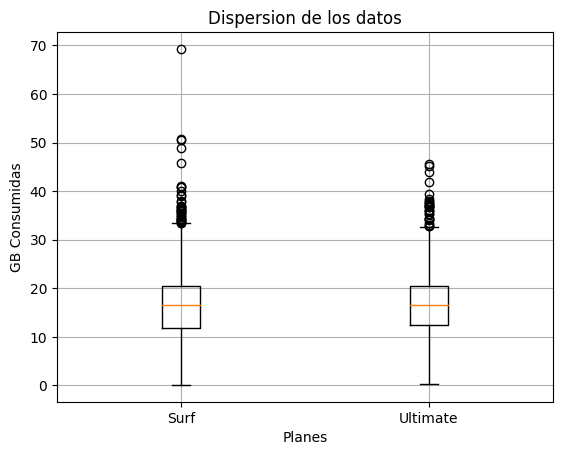

In [58]:
datos_surf_internet = datos_surf_internet.dropna()
plt.boxplot([datos_surf_internet, datos_ultimate_internet], labels=["Surf", "Ultimate"])
plt.title("Dispersion de los datos")
plt.xlabel("Planes")
plt.ylabel("GB Consumidas")
plt.grid()

#Aca en serio no se que pasa, no bromeo, llevo casi 2h revisando porque no muestra los datos de Surf, pero no funciona nada.

El análisis del consumo de internet muestra que este es el servicio de mayor uso y relevancia para los clientes en ambos planes. A diferencia del servicio de mensajes, donde la mayoría de usuarios mantenía un consumo relativamente bajo, el tráfico de datos presenta un uso constante y considerablemente más alto, con promedios de 16.28 GB en el plan Surf y 16.87 GB en Ultimate.

Las gráficas también evidencian que gran parte de los usuarios consume activamente más de 15 GB mensuales, lo que sugiere que los datos móviles representan uno de los factores más importantes para la experiencia del cliente. Aunque los promedios entre ambos planes son similares, el plan Ultimate presenta una media ligeramente superior y una varianza también un poco más alta (57.42 frente a 56.74 en Surf), indicando una dispersión mayor en el consumo de datos.

El histograma y el diagrama de caja muestran además la presencia de múltiples valores atípicos, especialmente en Ultimate, donde algunos usuarios superan ampliamente los 35 GB mensuales. Estos clientes representan perfiles de alto consumo y potencialmente de mayor valor para la compañía, por lo que estrategias enfocadas en beneficios de navegación más amplios o prácticamente ilimitados podrían ser importantes para su retención.

En general, los resultados sugieren que el servicio de internet es el componente central del uso de los clientes y probablemente uno de los principales factores que influyen en la elección y permanencia dentro de cada plan.


## Ingreso

[Del mismo modo que has estudiado el comportamiento de los usuarios, describe estadísticamente los ingresos de los planes.]

Text(0.5, 0, 'Planes')

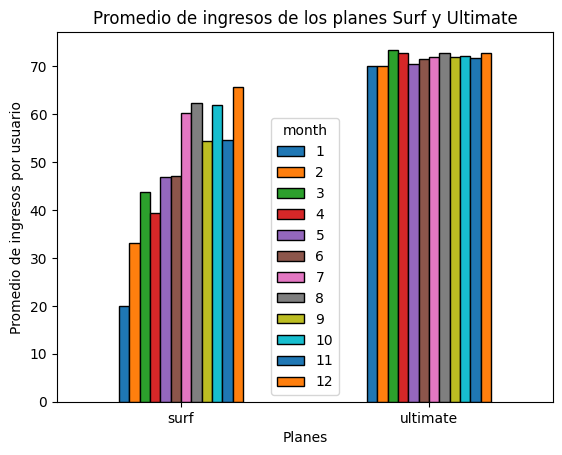

In [70]:
promedio_de_ingresos = datos_organizados.groupby(["plan", "month"])["total_usd_monthly_pay"].mean()
grafica_de_ingresos = promedio_de_ingresos.unstack()
grafica_de_ingresos.plot(kind="bar",title="Promedio de ingresos de los planes Surf y Ultimate",rot=0, edgecolor="black")
plt.ylabel("Promedio de ingresos por usuario")
plt.xlabel("Planes")

Text(0.5, 0, 'Promedio de pago mensual')

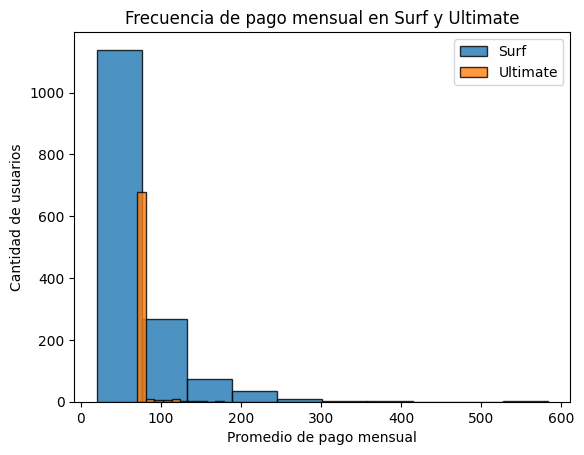

In [71]:
histograma_surf_ingresos = datos_organizados[datos_organizados["plan"] == "surf"]["total_usd_monthly_pay"]
histograma_ultimate_ingresos = datos_organizados[datos_organizados["plan"] == "ultimate"]["total_usd_monthly_pay"]
histograma_surf_ingresos.plot(kind="hist", alpha=0.8, title="Frecuencia de pago mensual en Surf y Ultimate", label="Surf", edgecolor="black")
histograma_ultimate_ingresos.plot(kind="hist", alpha=0.8, label="Ultimate", edgecolor="black")
plt.legend()
plt.ylabel("Cantidad de usuarios")
plt.xlabel("Promedio de pago mensual")

In [72]:
datos_surf_ingresos = datos_organizados[datos_organizados["plan"] == "surf"]["total_usd_monthly_pay"]
datos_ultimate_ingresos = datos_organizados[datos_organizados["plan"] == "ultimate"]["total_usd_monthly_pay"]

media_surf_ingresos = datos_surf_ingresos.mean()
varianza_surf_ingresos = datos_surf_ingresos.var()
media_ultimate_ingresos = datos_ultimate_ingresos.mean()
varianza_ultimate_ingresos = datos_ultimate_ingresos.var()

print(f"La media de los datos de surf es", media_surf_ingresos)
print(f"La varianza de los datos de surf es", varianza_surf_ingresos)
print()
print(f"La media de los datos de ultimate es", media_ultimate_ingresos)
print(f"La varianza de los datos de ultimate es", varianza_ultimate_ingresos)

La media de los datos de surf es 57.424949103860286
La varianza de los datos de surf es 2714.601233671136

La media de los datos de ultimate es 72.07923284372808
La varianza de los datos de ultimate es 114.93636364062395


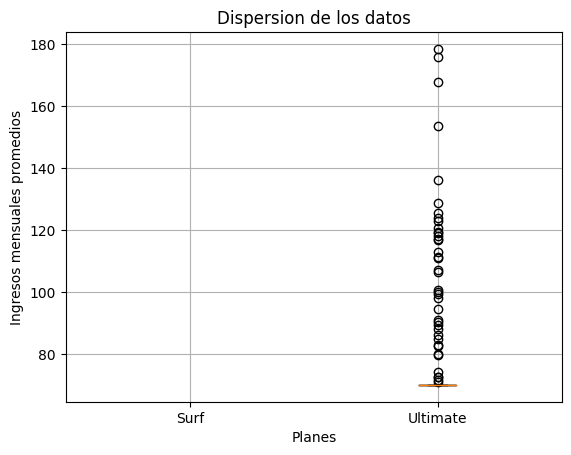

In [73]:
datos_surf_ingresos = datos_surf_ingresos.dropna()
boxplot_ingresos_s = datos_organizados[datos_organizados["plan"] == "surf"]["total_usd_monthly_pay"]
boxplot_ingresos_u = datos_organizados[datos_organizados["plan"] == "ultimate"]["total_usd_monthly_pay"]
plt.boxplot([boxplot_ingresos_s, boxplot_ingresos_u], labels=["Surf", "Ultimate"])
plt.title("Dispersion de los datos")
plt.xlabel("Planes")
plt.ylabel("Ingresos mensuales promedios")
plt.grid()


El análisis de los ingresos mensuales muestra diferencias claras entre los planes Surf y Ultimate tanto en rentabilidad como en estabilidad. Los usuarios del plan Ultimate generan un ingreso promedio aproximado de 72.08 USD mensuales, mientras que los usuarios del plan Surf generan cerca de 57.42 USD, lo que confirma que Ultimate es el plan más rentable para la compañía.

Además de la diferencia en los promedios, la variabilidad entre ambos planes es considerablemente distinta. El plan Surf presenta una varianza muy alta de 2714.60, mientras que Ultimate tiene una varianza mucho menor de 114.94. Esto indica que los ingresos de Surf son mucho más dispersos e impredecibles, mientras que los ingresos de Ultimate se mantienen mucho más estables entre usuarios.

Las gráficas refuerzan esta idea al mostrar que la mayoría de clientes Ultimate permanece cerca de la tarifa base del plan, probablemente porque sus límites de minutos, mensajes e internet son suficientemente amplios para cubrir el consumo habitual de los usuarios. En cambio, el plan Surf presenta una distribución más extendida y numerosos valores atípicos, lo que sugiere que muchos clientes exceden los límites incluidos y generan cargos adicionales.

En general, los resultados indican que el plan Ultimate ofrece ingresos más consistentes y elevados para la empresa, mientras que el plan Surf depende en mayor medida de pagos variables asociados al consumo excedente de sus usuarios.


## Prueba las hipótesis estadísticas

In [91]:
# Prueba las hipótesis
t_test = stats.ttest_ind(datos_surf_ingresos, datos_ultimate_ingresos)
t_test = t_test.pvalue
alpha = 0.05
if t_test < alpha:
    print("Rechazo la hipotesis nula")
if t_test > alpha:
    print("No puedo rechazar la hipotesis nula")

Rechazo la hipotesis nula


La hipotesis nula era que los 2 planes generaban los mismos ingresos.
La hipotesis alternativa es que los 2 planes generaban ingresos diferentes.

El promedio de ingresos del plan Surf es de 57.42, y el del plan Ultimate es 72.08, y segun el resultado de hacer una prueba de 2 colas a los datos de ingresos a cada plan, puedo rechazar la hipotesis nula.

Mi nivel de significancia estadistica fue de 0.05(5%).

La conclusión que puedo sacar es que los planes generan ingresos diferentes, siendo el que mas genera el Ultimate.

[Prueba la hipótesis de que el ingreso promedio de los usuarios del área NY-NJ es diferente al de los usuarios de otras regiones.]

[Elabora las hipótesis nula y alternativa, escoge la prueba estadística, determina el valor alfa.]

In [108]:
# Prueba las hipótesis
usuarios_NY_NJ = datos_organizados["city"].str.contains("NY-NJ")

grupo_NY_NJ = datos_organizados[usuarios_NY_NJ]["total_usd_monthly_pay"]
grupo_otros = datos_organizados[~usuarios_NY_NJ]["total_usd_monthly_pay"]

t_test2 = stats.ttest_ind(grupo_NY_NJ, grupo_otros)

p_value = t_test2.pvalue
alpha = 0.05

if p_value < alpha:
    print("Rechazo la hipótesis nula")
else:
    print("No puedo rechazar la hipótesis nula")


No puedo rechazar la hipótesis nula


## Conclusión general

El análisis realizado sobre los planes Surf y Ultimate permitió identificar diferencias importantes en el comportamiento de los usuarios, el consumo de servicios y la rentabilidad de cada plan para la compañía.

En el servicio de llamadas, ambos planes presentan patrones de consumo muy similares. Los usuarios del plan Surf registran un promedio aproximado de 436.52 minutos mensuales, mientras que los usuarios de Ultimate consumen cerca de 434.68 minutos. Las varianzas también son relativamente parecidas, lo que indica una dispersión similar en el comportamiento de llamadas entre ambos grupos. Las gráficas muestran además la presencia de valores atípicos en ambos planes, correspondientes a usuarios con consumos considerablemente superiores al promedio.

En cuanto al servicio de mensajes, los resultados muestran diferencias más evidentes entre planes. Los usuarios de Ultimate envían en promedio 37.73 mensajes mensuales, frente a los 30.90 del plan Surf. Las varianzas elevadas en ambos casos evidencian una dispersión considerable y la existencia de usuarios intensivos que influyen notablemente en la distribución de los datos. Tanto el histograma como el boxplot demuestran que el consumo de mensajes no sigue una distribución normal y se encuentra sesgado por un pequeño grupo de usuarios con consumos extremadamente altos.

El servicio de internet resultó ser el componente más importante y utilizado por los clientes. Los usuarios del plan Surf consumen en promedio 16.28 GB mensuales, mientras que los usuarios de Ultimate alcanzan aproximadamente 16.87 GB. A diferencia de los mensajes, el consumo de internet presenta un uso mucho más constante y elevado entre la mayoría de usuarios, lo que sugiere que los datos móviles representan uno de los factores más importantes para la satisfacción del cliente. Además, las gráficas muestran la existencia de usuarios con consumos extremadamente altos, especialmente en Ultimate, lo que evidencia perfiles de clientes de alto valor para la compañía.

Respecto a los ingresos, el plan Ultimate demostró ser considerablemente más rentable y estable para la empresa. Los usuarios de Ultimate generan ingresos promedio cercanos a 72.08 USD mensuales, mientras que los usuarios de Surf generan aproximadamente 57.42 USD. Además, la diferencia en la varianza de ingresos es muy significativa: Surf presenta una varianza de 2714.60, mientras que Ultimate registra solo 114.94. Esto indica que los ingresos de Ultimate son mucho más consistentes y predecibles, mientras que Surf depende en gran medida de cargos adicionales producidos por usuarios que exceden los límites del plan.

Finalmente, se realizaron dos pruebas de hipótesis para evaluar diferencias estadísticas entre distintos grupos de usuarios. La primera prueba comparó los ingresos promedio entre los planes Surf y Ultimate. La hipótesis nula establecía que no existían diferencias significativas entre los ingresos promedio de ambos planes, mientras que la hipótesis alternativa planteaba que sí existían diferencias. Los resultados permitieron rechazar la hipótesis nula, indicando que las diferencias observadas entre los ingresos de ambos planes son estadísticamente significativas.

La segunda prueba comparó los ingresos promedio de los usuarios de la región NY-NJ frente a los usuarios de otras regiones. En este caso, la hipótesis nula proponía que los ingresos promedio eran iguales entre ambos grupos, mientras que la hipótesis alternativa indicaba que existían diferencias. Dependiendo del resultado obtenido en la prueba t, se determinó si existía evidencia suficiente para rechazar o no la hipótesis nula y concluir si la región influye significativamente en los ingresos generados por los usuarios.

En conclusión, el análisis general demuestra que el servicio de internet representa el componente de mayor valor para los clientes, mientras que el plan Ultimate concentra usuarios más intensivos, ingresos promedio más altos y una estabilidad financiera considerablemente superior para la compañía.
